<a href="https://colab.research.google.com/github/maxiangt/MSSP6070/blob/main/Modules/Week_9/week9_Image_Downloader.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install requests beautifulsoup4

In [ ]:

import requests
import os
import time
from bs4 import BeautifulSoup
from pathlib import Path
from urllib.parse import urlparse

# Step 1: Search for Siamese cats
url = "https://www.flickr.com/search/?text=siamese+cat"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0.0.0 Safari/537.36",
    "Referer": "https://www.flickr.com/",
    "Accept": "image/avif,image/webp,image/apng,image/*,*/*;q=0.8"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

# Step 2: Extract image URLs
images = soup.find_all("img")

image_urls = []

for image in images:
    src = image.get("src")

    if src and "live.staticflickr.com" in src:
        if src.startswith("//"):
            src = "https:" + src

        if src not in image_urls:
            image_urls.append(src)

print("Siamese cat images found:", len(image_urls))

# Step 3: Create a new folder
save_folder = "/content/Siamese_Cat_Images"
os.makedirs(save_folder, exist_ok=True)

# Step 4: Download images
downloaded_count = 0

for index, image_url in enumerate(image_urls, start=1):
    try:
        img_response = requests.get(
            image_url, headers=headers, timeout=20
        )
        img_response.raise_for_status()

        if not img_response.headers.get(
            "Content-Type", ""
        ).startswith("image/"):
            continue

        extension = Path(urlparse(image_url).path).suffix

        if extension.lower() not in [".jpg", ".jpeg", ".png", ".webp"]:
            extension = ".jpg"

        filename = f"siamese_cat_{index}{extension}"

        with open(os.path.join(save_folder, filename), "wb") as f:
            f.write(img_response.content)

        downloaded_count += 1
        print("Downloaded:", filename)

        time.sleep(0.5)

    except requests.RequestException as error:
        print("Download failed:", error)

print("\nDownload completed!")
print("Total downloaded:", downloaded_count)


Siamese cat images found: 25
Downloaded: siamese_cat_1.jpg
Downloaded: siamese_cat_2.jpg
Downloaded: siamese_cat_3.jpg
Downloaded: siamese_cat_4.jpg
Downloaded: siamese_cat_5.jpg
Downloaded: siamese_cat_6.jpg
Downloaded: siamese_cat_7.jpg
Downloaded: siamese_cat_8.jpg
Downloaded: siamese_cat_9.jpg
Downloaded: siamese_cat_10.jpg
Downloaded: siamese_cat_11.jpg
Downloaded: siamese_cat_12.jpg
Downloaded: siamese_cat_13.jpg
Downloaded: siamese_cat_14.jpg
Downloaded: siamese_cat_15.jpg
Downloaded: siamese_cat_16.jpg
Downloaded: siamese_cat_17.jpg
Downloaded: siamese_cat_18.jpg
Downloaded: siamese_cat_19.jpg
Downloaded: siamese_cat_20.jpg
Downloaded: siamese_cat_21.jpg
Downloaded: siamese_cat_22.jpg
Downloaded: siamese_cat_23.jpg
Downloaded: siamese_cat_24.jpg
Downloaded: siamese_cat_25.jpg

Download completed!
Total downloaded: 25


Total saved images: 25


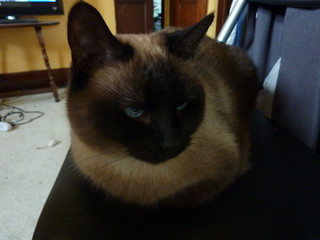

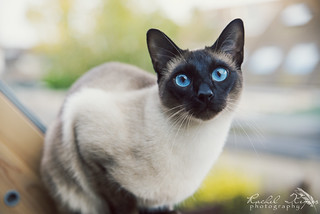

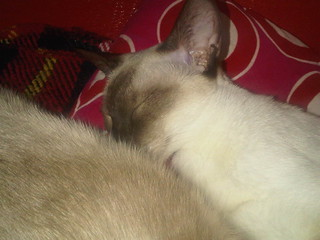

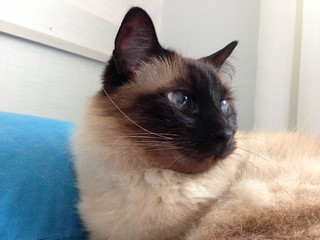

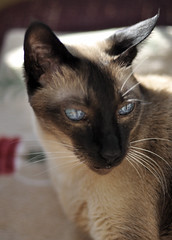

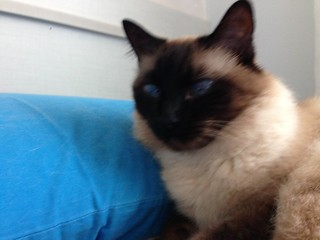

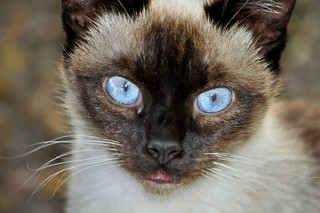

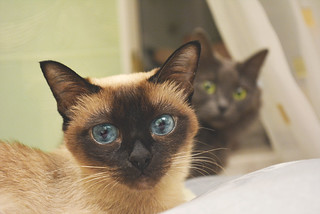

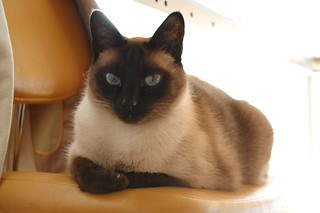

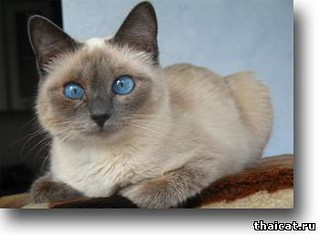

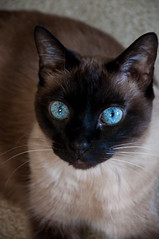

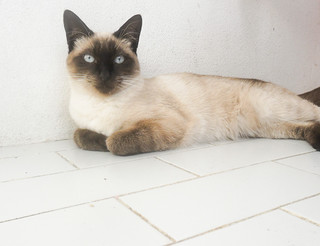

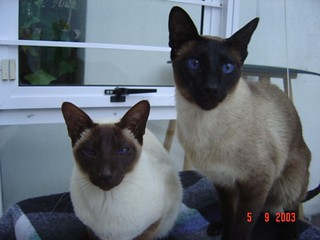

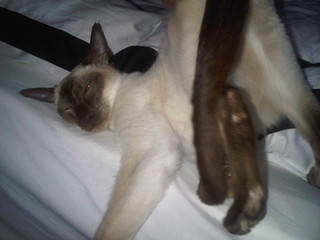

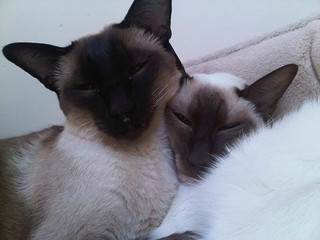

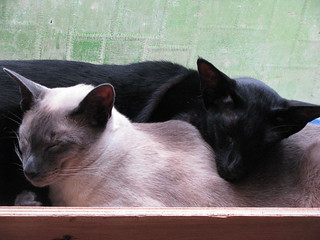

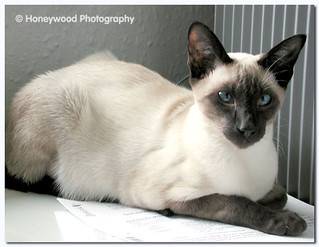

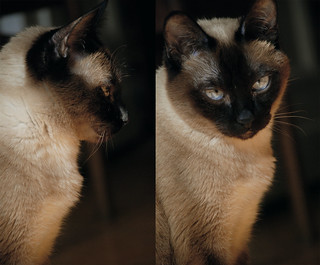

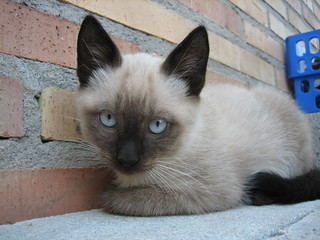

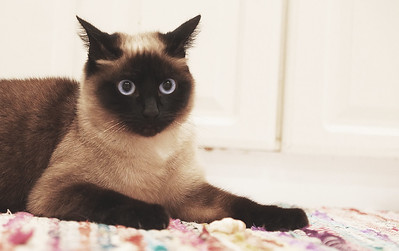

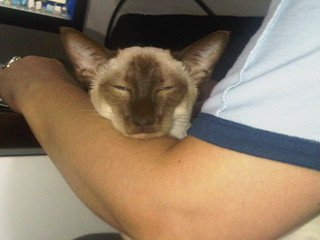

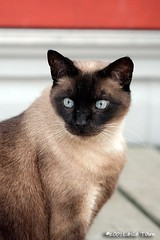

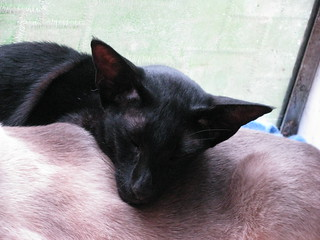

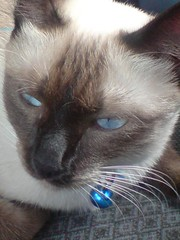

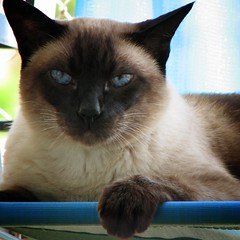

In [ ]:
from PIL import Image
from IPython.display import display
import glob

image_files = glob.glob(
    "/content/Siamese_Cat_Images/*"
)

print("Total saved images:", len(image_files))

for file in image_files:
    display(Image.open(file))